In [1]:
# load data, run Stage 1 (quality), Stage 2 (Kalman) and the indicators of Stage 3
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from data_quality import run_quality_checks
from kalman_filter import run_kalman_stage
from entropy_weighting import INDICATORS, make_indicators, normalize, entropy_weights
from load_data import load_raw, load_health

raw = load_raw()
filtered = run_kalman_stage(run_quality_checks(raw))

# the fault type is only used to CHECK the grade, never to make it
ref = load_health()
filtered = filtered.merge(ref[["record_id", "label"]], on="record_id", how="left")
filtered["fault"] = filtered["label"]

ind = make_indicators(filtered)
print("Rows:", len(ind))

Rows: 196055


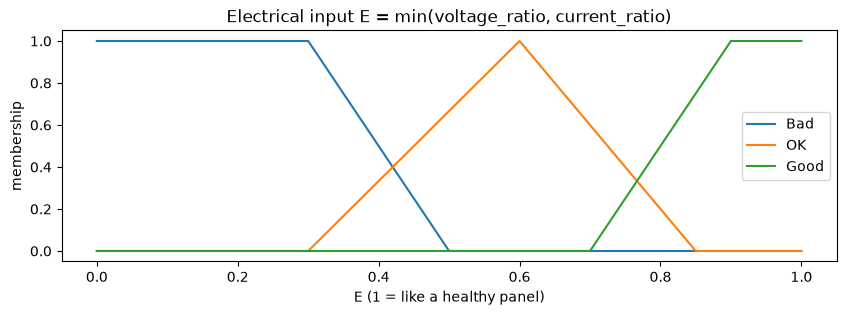

E = 0.8 -> Bad 0.0 | OK 0.2 | Good 0.5


In [2]:
# trap() and tri() - membership functions

def trap(x, a, b, c, d):
    # trapezoid membership: 0 before a, rises a->b, 1 from b to c, falls c->d
    x = np.asarray(x, dtype=float)
    y = np.zeros_like(x)
    y = np.where((x >= b) & (x <= c), 1.0, y)
    if b > a:
        y = np.where((x >= a) & (x < b), (x - a) / (b - a), y)
    if d > c:
        y = np.where((x > c) & (x <= d), (d - x) / (d - c), y)
    return y


def tri(x, a, b, c):
    # triangle membership: peak at b
    return trap(x, a, b, b, c)


# ---- test: the three sets of the electrical input E ----
e = np.linspace(0, 1, 201)
plt.figure(figsize=(10, 3))
plt.plot(e, trap(e, 0, 0, 0.3, 0.5), label="Bad")
plt.plot(e, tri(e, 0.3, 0.6, 0.85), label="OK")
plt.plot(e, trap(e, 0.7, 0.9, 1, 1), label="Good")
plt.title("Electrical input E = min(voltage_ratio, current_ratio)")
plt.xlabel("E (1 = like a healthy panel)")
plt.ylabel("membership")
plt.legend()
plt.show()

# E = 0.8 is a bit OK and a bit Good at the same time
print("E = 0.8 -> Bad", trap(0.8, 0, 0, 0.3, 0.5), "| OK", round(float(tri(0.8, 0.3, 0.6, 0.85)), 2),
      "| Good", round(float(trap(0.8, 0.7, 0.9, 1, 1)), 2))

In [3]:
# indicator_scores() and combined_weights()

ENTROPY_SHARE = 0.5     # half from entropy, half shared equally
TEMP_RISE_BAD = 20.0    # C above a healthy panel
DUST_BAD = 30.0         # % (DSM501B)


def indicator_scores(ind):
    # every indicator on the same scale: 1 = good, 0 = bad
    scores = pd.DataFrame(index=ind.index)
    scores["power_ratio"] = ind["power_ratio"]
    scores["voltage_ratio"] = ind["voltage_ratio"]
    scores["current_ratio"] = ind["current_ratio"]
    scores["temp_rise"] = ((TEMP_RISE_BAD - ind["temp_rise"]) / TEMP_RISE_BAD).clip(0, 1)
    scores["dust_level"] = ((DUST_BAD - ind["dust_level"]) / DUST_BAD).clip(0, 1)
    return scores


def combined_weights(ind):
    # entropy weights mixed with equal weights
    w = entropy_weights(normalize(ind))
    return ENTROPY_SHARE * w + (1 - ENTROPY_SHARE) / len(INDICATORS)


# ---- test ----
scores = indicator_scores(ind)
weights = combined_weights(ind)

print("Weights:")
print(pd.DataFrame({"entropy only": entropy_weights(normalize(ind)), "used (50/50)": weights}).round(3))
print()

# weighted score (Stage 3 output, 0 - 100)
S = (scores[list(INDICATORS)] * weights[list(INDICATORS)]).sum(axis=1) * 100
print("Median weighted score for each fault type:")
print(S.groupby(ind["fault"]).median().round(1))

Weights:
               entropy only  used (50/50)
power_ratio           0.274         0.237
voltage_ratio         0.150         0.175
current_ratio         0.133         0.166
temp_rise             0.418         0.309
dust_level            0.026         0.113

Median weighted score for each fault type:
fault
DARK               61.5
DUST               77.8
NORMAL             97.5
OPEN_CIRCUIT       40.8
PARTIAL_SHADING    65.5
SHORT_CIRCUIT      60.4
dtype: float64


In [4]:
# fuzzy_grade() - 7 rules, then centroid

def fuzzy_grade(S, E, T, D):
    # S = weighted score (0-100), E = electrical, T = thermal, D = dust (1 = good)

    # ---- fuzzify ----
    s_low, s_med, s_high = trap(S, 0, 0, 30, 50), tri(S, 30, 55, 80), trap(S, 65, 85, 100, 100)
    e_bad, e_ok, e_good = trap(E, 0, 0, 0.3, 0.5), tri(E, 0.3, 0.6, 0.85), trap(E, 0.7, 0.9, 1, 1)
    t_hot, t_normal = trap(T, 0, 0, 0.25, 0.5), trap(T, 0.25, 0.5, 1, 1)
    d_dirty, d_clean = trap(D, 0, 0, 0.4, 0.6), trap(D, 0.4, 0.6, 1, 1)

    # ---- rules (AND = min) ----
    rules = np.vstack([
        e_bad,                                                   # R1 -> FAULTY
        t_hot,                                                   # R2 -> FAULTY
        np.minimum(s_low, 1 - e_good),                           # R3 -> FAULTY
        np.minimum(s_med, 1 - e_bad),                            # R4 -> DEGRADED
        np.minimum(d_dirty, 1 - e_bad),                          # R5 -> DEGRADED
        e_ok,                                                    # R6 -> DEGRADED
        np.minimum.reduce([s_high, e_good, t_normal, d_clean]),  # R7 -> HEALTHY
    ])

    # ---- combine rules of the same output (OR = max) ----
    faulty = rules[0:3].max(axis=0)
    degraded = rules[3:6].max(axis=0)
    healthy = rules[6]

    # ---- defuzzify (centroid over 0..100) ----
    y = np.arange(101)[:, None]
    mu = np.maximum.reduce([
        np.minimum(faulty, trap(y, 0, 0, 20, 40)),
        np.minimum(degraded, tri(y, 30, 50, 70)),
        np.minimum(healthy, trap(y, 60, 80, 100, 100)),
    ])
    total = mu.sum(axis=0)
    health = np.where(total > 1e-6, (mu * y).sum(axis=0) / np.maximum(total, 1e-9), S)

    return health


def health_status(score):
    # NaN score = not graded (too dark)
    score = np.asarray(score, dtype=float)
    return np.where(np.isnan(score), "NOT_GRADED",
           np.where(score >= 70, "HEALTHY",
           np.where(score >= 40, "DEGRADED", "FAULTY")))


# ---- test on one row of each fault type ----
E = scores[["voltage_ratio", "current_ratio"]].min(axis=1)
health = fuzzy_grade(S.to_numpy(), E.to_numpy(),
                           scores["temp_rise"].to_numpy(), scores["dust_level"].to_numpy())

print(f"{'fault':<16}{'weighted':>10}{'':>11}{'E':>7}{'fuzzy':>8}   status")
for f in ["NORMAL", "DUST", "PARTIAL_SHADING", "OPEN_CIRCUIT", "SHORT_CIRCUIT"]:
    rows = ind.index[(ind["fault"] == f) & (ind["irradiance_lux"] > 20000)]   # daytime rows
    if f == "SHORT_CIRCUIT":   # a short that data quality found (LOAD_SHORTED)
        rows = ind.index[(ind["fault"] == f) & ind["quality_flag"].str.contains("LOAD_SHORTED")]
    i = rows[100]          # the 100th row of this fault type
    print(f"{f:<16}{S[i]:>10.1f} {health_status(S[i]):<10}{E[i]:>7.2f}{health[i]:>8.1f}   {health_status(health[i])}")

fault             weighted                 E   fuzzy   status
NORMAL                98.1 HEALTHY      1.00    84.7   HEALTHY
DUST                  85.2 HEALTHY      0.92    50.0   DEGRADED
PARTIAL_SHADING       63.6 DEGRADED     0.53    50.0   DEGRADED
OPEN_CIRCUIT          41.1 DEGRADED     0.00    15.3   FAULTY
SHORT_CIRCUIT         59.1 DEGRADED     0.02    15.3   FAULTY


In [5]:
# run_fuzzy_stage() - grade every row

# no grading in the dark (power is 0 at night, that is not a fault)
MIN_GRADING_LUX = 50.0


def run_fuzzy_stage(df):
    # input: output of run_kalman_stage(), output: the same rows with the grade
    df = df.copy()
    ind = make_indicators(df)
    scores = indicator_scores(ind)
    weights = combined_weights(ind)

    S = (scores[list(INDICATORS)] * weights[list(INDICATORS)]).sum(axis=1) * 100
    E = scores[["voltage_ratio", "current_ratio"]].min(axis=1)
    health = fuzzy_grade(S.to_numpy(), E.to_numpy(),
                               scores["temp_rise"].to_numpy(), scores["dust_level"].to_numpy())

    # too dark to grade: no score (left out when sent to the backend)
    dark = (df["irradiance_lux"] < MIN_GRADING_LUX).to_numpy()
    health = np.where(dark, np.nan, health)

    df["weighted_score"] = S.where(~dark).round(2)
    df["health_score"] = np.round(health, 2)
    df["health_status"] = health_status(health)
    return df


# ---- test: how many rows get the right grade? ----
graded = run_fuzzy_stage(filtered)
expected = graded["fault"].map({"NORMAL": "HEALTHY",
                                "DUST": "DEGRADED", "PARTIAL_SHADING": "DEGRADED",
                                "OPEN_CIRCUIT": "FAULTY", "SHORT_CIRCUIT": "FAULTY",
                                "DARK": "NOT_GRADED"})
# too dark to grade -> the right answer is NOT_GRADED (whatever the label)
expected[graded["irradiance_lux"] < MIN_GRADING_LUX] = "NOT_GRADED"

fuzzy_ok = (graded["health_status"] == expected).mean()
weighted_ok = (health_status(graded["weighted_score"]) == expected).mean()
print(f"Weighted score only : {weighted_ok:.1%} correct")
print(f"Fuzzy logic         : {fuzzy_ok:.1%} correct")
print()
print("Fuzzy grade for each fault type:")
print(pd.crosstab(graded["fault"], graded["health_status"]))
print()
print("Weighted score grade for each fault type:")
print(pd.crosstab(graded["fault"], health_status(graded["weighted_score"])))

# ---- final check: notebook code = src/fuzzy_logic.py ----
import fuzzy_logic
from_file = fuzzy_logic.run_fuzzy_stage(filtered)
print()
print("Notebook code = src/fuzzy_logic.py:",
      np.allclose(graded["health_score"], from_file["health_score"], equal_nan=True) and
      graded["health_status"].equals(from_file["health_status"]))

Weighted score only : 97.7% correct
Fuzzy logic         : 97.9% correct

Fuzzy grade for each fault type:
health_status    DEGRADED  FAULTY  HEALTHY  NOT_GRADED
fault                                                 
DARK                  128     353      122        1608
DUST                  693       0       19           0
NORMAL               1981     232   182360         316
OPEN_CIRCUIT            4     706        0           0
PARTIAL_SHADING      5993      68      831           0
SHORT_CIRCUIT           3     335      303           0

Weighted score grade for each fault type:
col_0            DEGRADED  FAULTY  HEALTHY  NOT_GRADED
fault                                                 
DARK                  413       2      188        1608
DUST                  156       0      556           0
NORMAL                547       0   184026         316
OPEN_CIRCUIT          610     100        0           0
PARTIAL_SHADING      5330       0     1562           0
SHORT_CIRCUIT         333 